# Which revenue forecast should Anand put in front of Kalpa's board, and how wrong could it be?

**Week 4, Friday, the TA lab: the same method on Kalpa Retail.** Kalpa Retail's growth plan
goes to the board and needs a number: revenue for October 2026 to March 2027, against a
plan line 15 percent above the same months a year earlier, with Diwali inside the window.
Finance's forecast is last year plus 4 percent; marketing's vendor curve promises 22
percent. Anand Iyer, the finance controller: "Two forecasts, eighteen points apart. Which
one do I put in front of the board, and how wrong could it be?" The data hold 24 months of
revenue, October 2024 to September 2026; April to September 2026 are the monthly sums of
the 1,000 orders in the Week 2 warehouse. Diwali fell on 31 October 2024 and 20 October
2025, and falls on 8 November 2026.

**Who needs the answer.** Anand, who signs the board number, and the head of Retail-Plus,
whose stock and staff follow it. A number the board holds Kalpa to for two quarters costs
either a missed promise or idle stock.

**The questions on the way.** What shape do the two winters have? How do naive and drift
score on April to September 2026? How do the seasonal copy and the vendor score? Which month
does each copy put Diwali in this year?

In [1]:
import math
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.figsize": (9, 3.8), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

def check(name, ok):
    print(("PASS " if ok else "FAIL ") + name)

rev = pd.read_csv("../data/C2_W04_D05_kalpa_monthly_revenue_STUDENT.csv").set_index("month").revenue_rs
vendor = pd.read_csv("../data/C2_W04_D05_kalpa_vendor_forecast_STUDENT.csv").set_index("month")
plan = pd.read_csv("../data/C2_W04_D05_kalpa_plan_line_STUDENT.csv").set_index("month").plan_rs
print(f"{len(rev)} months, {rev.index[0]} to {rev.index[-1]}")
print(f"Apr to Jun 2026: Rs {rev['2026-04':'2026-06'].sum() / 1e7:.2f} crore; Jul to Sep: Rs {rev['2026-07':'2026-09'].sum() / 1e7:.2f} crore")
check("24 months", len(rev) == 24)
check("the two quarters match the warehouse", (rev['2026-04':'2026-06'].sum(), rev['2026-07':'2026-09'].sum()) == (100_000_000, 98_400_000))

24 months, 2024-10 to 2026-09
Apr to Jun 2026: Rs 10.00 crore; Jul to Sep: Rs 9.84 crore
PASS 24 months
PASS the two quarters match the warehouse


## What shape do the two winters have?

Twelve rows: October to March of 2024-25 and of 2025-26, in Rs lakh.

**Predict before you run.** Which month is the biggest of each winter?

     2024-25  2025-26
Oct    415.1    427.6
Nov    286.8    297.0
Dec    295.8    310.5
Jan    275.9    285.1
Feb    267.4    275.7
Mar    284.6    297.0


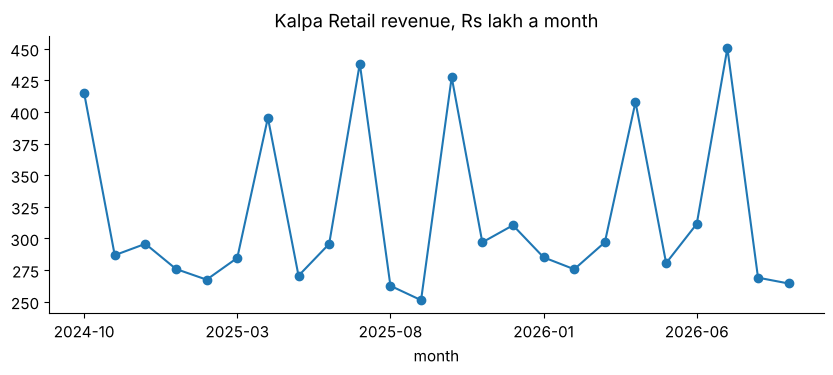

PASS October is each winter's biggest month


In [2]:
winters = pd.DataFrame({"2024-25": rev["2024-10":"2025-03"].values, "2025-26": rev["2025-10":"2026-03"].values},
                       index=["Oct", "Nov", "Dec", "Jan", "Feb", "Mar"]) / 1e5
print(winters.round(1).to_string())
(rev / 1e5).plot(marker="o", title="Kalpa Retail revenue, Rs lakh a month", figsize=(10, 3.6))
plt.show()
check("October is each winter's biggest month", list(winters.idxmax()) == ["Oct", "Oct"])

## How do naive and drift score on April to September 2026?

Hide the last six months and forecast them from March 2026. Naive repeats March; drift
extends the line from October 2024 through March 2026. The score is MAE in Rs lakh.

naive MAE: Rs 59.4 lakh   drift MAE: Rs 58.8 lakh


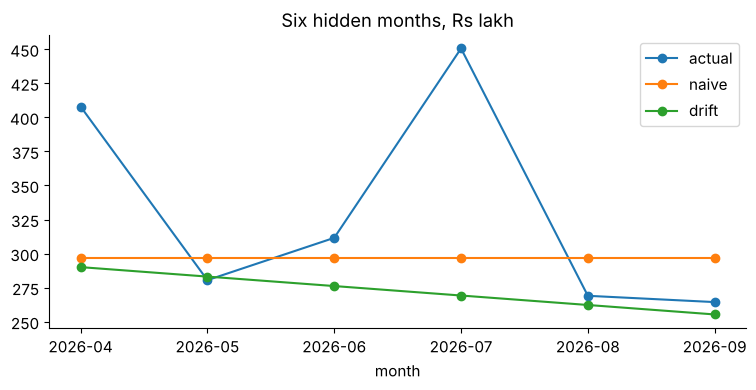

PASS naive misses by more than Rs 50 lakh a month


In [3]:
hold = rev["2026-04":"2026-09"]
months_ahead = pd.Series(range(1, 7), index=hold.index)
naive = pd.Series(rev["2026-03"], index=hold.index)
drift = rev["2026-03"] + months_ahead * (rev["2026-03"] - rev["2024-10"]) / 17

def mae(f):
    return (f - hold).abs().mean() / 1e5

print(f"naive MAE: Rs {mae(naive):.1f} lakh   drift MAE: Rs {mae(drift):.1f} lakh")
pd.DataFrame({"actual": hold, "naive": naive, "drift": drift}).div(1e5).plot(marker="o", title="Six hidden months, Rs lakh")
plt.show()
check("naive misses by more than Rs 50 lakh a month", mae(naive) > 50)

## How do the seasonal copy and the vendor score on the same six months?

**Your turn.** Score the seasonal copy (the same month a year earlier) and the vendor's
forecast on the same six months. Type these lines into the empty cell below and run them:

```python
seasonal = rev.shift(12).loc[hold.index]
vendor_hold = vendor.loc[hold.index, "vendor_rs"]
print(vendor.loc[hold.index, "kind"].unique())
print(f"seasonal MAE: Rs {mae(seasonal):.1f} lakh   vendor MAE: Rs {mae(vendor_hold):.1f} lakh")
```

## Which month does each copy put Diwali in this year?

Diwali 2026 falls on 8 November. The month-aligned copy takes each month from the same month
last year; the festival-aligned copy moves last year's Diwali month to this year's and puts
last year's November in October's place, then adds 4 percent.

**Your turn.** Type these lines into the empty cell below:

```python
months = ["2026-10", "2026-11", "2026-12", "2027-01", "2027-02", "2027-03"]
last = [rev[f"{int(m[:4]) - 1}{m[4:]}"] for m in months]
aligned = [rev["2025-11"], rev["2025-10"]] + last[2:]
table = pd.DataFrame({"month-aligned": last, "festival-aligned": [round(a * 1.04) for a in aligned],
                      "vendor": vendor.loc[months, "vendor_rs"].values, "plan line": plan.loc[months].values},
                     index=months) / 1e5
print(table.round(1).to_string())
print(table.sum().round(1).to_string())
```

the second year grew 3.7% on the first
plan line, Oct 2026 to Mar 2027: Rs 21.77 crore


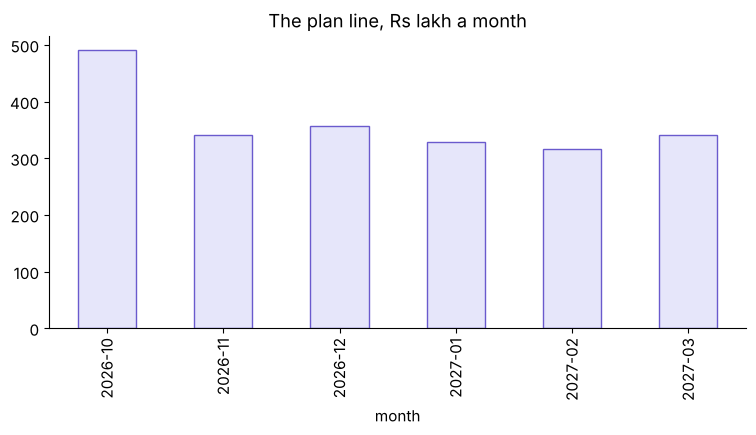

PASS the plan line is 15 percent above last year's same months


In [4]:
growth = rev["2025-10":"2026-09"].sum() / rev["2024-10":"2025-09"].sum() - 1
print(f"the second year grew {growth:.1%} on the first")
print(f"plan line, Oct 2026 to Mar 2027: Rs {plan.sum() / 1e7:.2f} crore")
(plan / 1e5).plot.bar(color="lavender", edgecolor="slateblue", title="The plan line, Rs lakh a month")
plt.show()
check("the plan line is 15 percent above last year's same months",
      abs(plan.sum() / rev["2025-10":"2026-03"].sum() - 1.15) < 0.001)

## What do you bring to the TA, in rupees?

Anand's board number in one paragraph: the forecast you would send, the months it puts the
spike in, its error bar in Rs lakh from the six hidden months, and the gap to the plan line.
The unguided exercise `exercises/unguided/C2_W04_D05_kalpa_board_STUDENT.md` asks the same
decision in lettered items.

- **The two winters:** October is the biggest month of each.
- **Naive and drift:** they miss April to September 2026 by Rs 59.4 and Rs 58.8 lakh a month.
- **The seasonal copy and the vendor:** your cell.
- **Diwali this year:** your cell.